In [1]:
import time, urllib.request
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.9.1 | urządzenie: cpu


In [2]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)
        self.features = nn.Sequential(block(1, 32), block(32, 64))  # 28 -> 14 -> 7
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def count(m): return sum(p.numel() for p in m.parameters())

x = torch.randn(2, 1, 28, 28)
for p in ["max", "avg", "stride"]:
    m = CNN(pool=p).eval()
    with torch.inference_mode():
        feat = m.features(x)
        logits = m.head(feat)
    print(f"pool={p:6} | parametry {count(m):>7,} | mapa przed głowicą {tuple(feat.shape)} | logity {tuple(logits.shape)}")
    

pool=max    | parametry  19,658 | mapa przed głowicą (2, 64, 7, 7) | logity (2, 10)
pool=avg    | parametry  19,658 | mapa przed głowicą (2, 64, 7, 7) | logity (2, 10)
pool=stride | parametry  66,026 | mapa przed głowicą (2, 64, 7, 7) | logity (2, 10)


In [3]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

def evaluate(model, dl):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); total += yb.numel()
    return correct/total

def train(model, epochs=6):
    model = model.to(device); crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3); accs = []
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        accs.append(evaluate(model, test_dl))
    return accs

results = {}
for p in ["max", "avg", "stride"]:
    torch.manual_seed(0)
    m = CNN(pool=p)
    accs = train(m, epochs=6)
    results[p] = (accs, count(m))
    print(f"pool={p:6} | best acc {max(accs)*100:.2f}% | parametry {count(m):,}")

pool=max    | best acc 81.34% | parametry 19,658
pool=avg    | best acc 80.80% | parametry 19,658
pool=stride | best acc 89.38% | parametry 66,026


| Wariant | Best acc | Parametry | Mapa przed głowicą |
| Max pooling | 81.34% | 19,658 | 64×7×7 |
| Average pooling | 80.80% | 19,658 | 64×7×7 |
| Splot stride=2 | 89.38% | 66,026 | 64×7×7 |


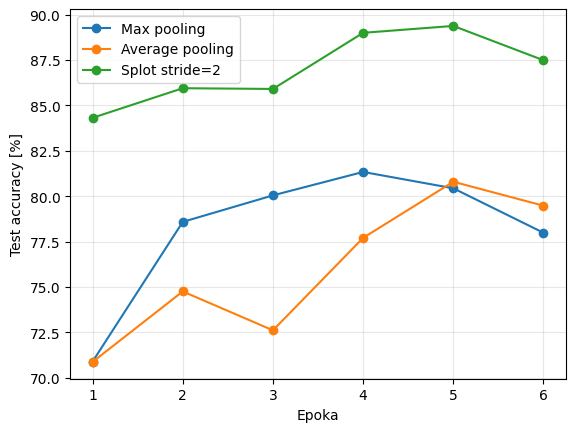

In [14]:
names = {"max": "Max pooling", "avg": "Average pooling", "stride": "Splot stride=2"}
print("| Wariant | Best acc | Parametry | Mapa przed głowicą |")
for p, (accs, n) in results.items():
    print(f"| {names[p]} | {max(accs)*100:.2f}% | {n:,} | 64×7×7 |")

for p, (accs, n) in results.items():
    plt.plot(range(1, len(accs)+1), [a*100 for a in accs], marker="o", label=names[p])
plt.xlabel("Epoka"); plt.ylabel("Test accuracy [%]"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("krzywe_accuracy.png", dpi=150, bbox_inches="tight"); plt.show()

In [15]:
print(f"{'pool':7} | {'parametry':>10} | {'best acc':>9}")
print('-'*34)
for p,(accs,n) in results.items():
    print(f"{p:7} | {n:>10,} | {max(accs)*100:>8.2f}%")

pool    |  parametry |  best acc
----------------------------------
max     |     19,658 |    81.34%
avg     |     19,658 |    80.80%
stride  |     66,026 |    89.38%
